# Question 1

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
import os
from netCDF4 import Dataset
import pandas as pd
import xarray as xr
from scipy.signal import detrend
from scipy.stats import chi2 as chi2_dist

In [21]:
@dataclass
class PierData:
    """A slice of the 2021 pier record. """
    dnum: np.ndarray          # times, as numpy datetime64[s]
    temperature: np.ndarray   # degrees C
    pressure: np.ndarray      # decibars
    readme: str = field(
        default='2021 Pier data, SIO221a, function get_2021_pier_data.py')

    def __len__(self):
        return len(self.dnum)

    
def get_pier_data(file, date_start=None, date_end=None):
    """Return temperature, pressure and time from the 2020 Scripps pier record.

    Parameters
    ----------
    date_start, date_end : numpy datetime64 or str, optional
        Bracket the period you want, e.g. '2020-06-04'.  Omit both to get the
        whole record.
    file : str, optional
        Path to the netCDF file.  Omit it and we find data/scripps_pier-2020.nc
        inside the class repo.

    Returns
    -------
    pier : PierData
    """

    nc = Dataset(file)
    try:
        time = np.asarray(nc.variables['time'][:])
        temperature = np.asarray(nc.variables['temperature'][:])
        pressure = np.asarray(nc.variables['pressure'][:])
    finally:
        nc.close()

    # netCDF time is seconds since 1970-01-01, which is exactly datetime64[s].
    dnum = time.astype('datetime64[s]')

    if date_start is None:
        i1 = np.ones(dnum.shape, dtype=bool)
    else:
        i1 = ((dnum > np.datetime64(date_start)) &
              (dnum < np.datetime64(date_end)))

    return PierData(dnum=dnum[i1],
                    temperature=temperature[i1],
                    pressure=pressure[i1])


def getManyPier(numyears, start, date_start=None, date_end=None):
    """
    converts from pier object to dictionary in order to append more easily

    takes in number of years to add together, starting year

    returns: PierData object 
    
    """
    pier_data = {"dnum":np.array([], dtype='datetime64[s]'), "temperature":np.array([]), "pressure":np.array([])} #make an initial dictionary to append all the data to
    for i in range(start,start+numyears):
        pier = get_pier_data(file= "../pier_data/scripps_pier-"+str(i)+".nc")
        pier_data["dnum"] = np.concatenate((pier_data["dnum"], pier.dnum)) #preserve the order, append new values to the end
        pier_data["temperature"] = np.concatenate((pier_data["temperature"], pier.temperature))
        pier_data["pressure"] = np.concatenate((pier_data["pressure"], pier.pressure))
    pier = PierData(dnum= pier_data["dnum"], temperature=pier_data["temperature"], pressure=pier_data["pressure"])
    return pier

In [31]:
pier = get_pier_data("../pier_data/scripps_pier-2021.nc")

Using the same range of data we used in homework 4.

In [32]:
pres = pier.pressure[70521:88190]
dates = pier.dnum[70521:88190]

In [ ]:
#just used same code from homework 4
updates = np.insert(dates, 15041, '2021-08-26T20:54:18')
updates = np.insert(updates, 7495, '2021-08-05T21:46:18')
updates = np.insert(updates, 4951, '2021-07-29T20:06:18')
updates = np.insert(updates, 2419, '2021-07-22T19:14:18')

newpres = np.insert(pres, 15041, np.mean(pres[15040:15042]))
newpres = np.insert(newpres, 7495, np.mean(pres[7494:7496]))
newpres = np.insert(newpres, 4951, np.mean(pres[4950:4952]))
newpres = np.insert(newpres, 2419, np.mean(pres[2418:2420]))

In [42]:
len(newpres)

17673

In [43]:
deP = detrend(newpres)
a = np.fft.fft(deP)
N = len(deP)
amp = np.abs(a[:(N+1)//2 + 1])**2 

dt = 240/(60*60*24)
T = dt*N
df = 1/T
fn = 1/2/dt
f = np.arange(0, ((N + 1) // 2 + 1) * df, df) 

amp = amp / N**2 
amp[1:-1] = amp[1:-1]*2 
amp = amp / df

In [50]:
#hanning window detrended
M = 10
p = N//M
w = np.hanning(p) # matches MATLAB's hann, not its hanning
scale = np.sqrt(8/3) # put back the energy the taper removed
starts = np.arange(0, N - p + 1, p//2)
Sc = np.zeros((p//2 + 1, len(starts)))
for k, s in enumerate(starts):
    sgi = detrend(deP[s:s+p])
    Xc = np.fft.fft(sgi*w*scale)
    tmp = np.abs(Xc[:p//2+1])**2 / p**2; tmp[1:-1] *= 2
    Sc[:, k] = tmp/(1/(dt*p))
Sc = np.mean(Sc, axis=1)
fbv = np.arange(0, fn + 1/(dt*p)/2, 1/(dt*p))

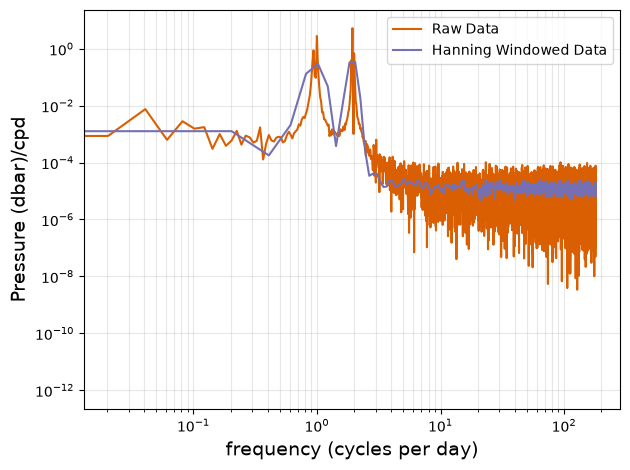

In [57]:
fig, ax = plt.subplots()
ax.loglog(f, amp, color = "#d95f02", label = "Raw Data")
ax.loglog(fbv, Sc, color = "#7570b3", label = "Hanning Windowed Data")
ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel('Pressure (dbar)/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

In [56]:
v0 = np.mean(deP**2)
print(f'variance of the record = {v0:.6e}')
print(f'integral, 1 segment = {np.sum(amp)*(1/(dt*N)):.6e} ratio {np.sum(amp)*(1/(dt*N))/v0:.4f}')
print(f'integral, Hanning + sqrt(8/3) = {np.sum(Sc)*(1/(dt*p)):.6e} ratio {np.sum(Sc)*(1/(dt*p))/v0:.4f}')

variance of the record = 2.415057e-01
integral, 1 segment = 2.415059e-01 ratio 1.0000
integral, Hanning + sqrt(8/3) = 2.467329e-01 ratio 1.0216


This is correctly normalized for the Hanning window (about 2% off from what the ratio should be, which is one). 

# Question 2

# Question 3

In [ ]:
def get_wind(file):
    """Return different types of wind speed measures from buoy measures.

    Parameters
    ----------
    file : str, optional
        Path to the netCDF file. 

    Returns
    -------
    wind : WindData
    """

    nc = Dataset(file)
    try:
        #fill_value = 9.969209968386869e36 #have to convert from julian date formatting to standard datetime
        #time_data = np.where(nc["TIME"] == fill_value, np.nan, nc["TIME"])
        #time_d = pd.to_datetime(time_data, unit="D", origin = "1950-01-01 00:00:00")
        #dnum = np.array(time_d.values)#.astype('datetime64[m]')
        dnum = np.ndarray.flatten(np.asarray(nc.variables['TIME'][:]))
        wspeed = np.ndarray.flatten(np.asarray(nc.variables['WSPD'][:]))
        zwind = np.ndarray.flatten(np.asarray(nc.variables['UWND'][:]))
        mwind = np.ndarray.flatten(np.asarray(nc.variables['VWND'][:]))

        #process and interpolate in advance
        nand = np.where(wspeed == -999.0, np.nan, wspeed)
        da = xr.DataArray(nand, dims="ws")

        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            dnum = dnum[0:47581]
            cleaned_np_array = cleaned_np_array[0:47581]
        wspeed = cleaned_np_array

        nand = np.where(zwind == -999.0, np.nan, zwind)
        da = xr.DataArray(nand, dims="ws")

        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            cleaned_np_array = cleaned_np_array[0:47581]
        zwind = cleaned_np_array


        nand = np.where(mwind == -999.0, np.nan, mwind)
        da = xr.DataArray(nand, dims="ws")
        
        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            cleaned_np_array = cleaned_np_array[0:47581]
        mwind = cleaned_np_array

    finally:
        nc.close()

    i1 = np.ones(dnum.shape, dtype=bool)

    return WindData(dnum=dnum[i1][:],
                    wspeed=wspeed[i1][:],
                    zwind=zwind[i1][:],
                    mwind = mwind[i1][:])
